In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt

sys.path.append('../')

from evaluate import evaluate
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import get_model
import utils
import pandas as pd

ModuleNotFoundError: No module named 'model.model'

In [ ]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [ ]:
classes = [ i for i in LABEL_MAPPING.keys()]

## Load models and their configs and dataloaders

In [12]:

    
models = {

    #'layer=1; kernel=15, sigma=1.5' : {
    #    'wandb_id' : '3yvsix81',
    #},
    'layer=2; kernel=15, sigma=1.5' : {
        'wandb_id' : '3yiwo9lk',
    },    
    #'layer=3; kernel=15, sigma=1.5' : {
    #    'wandb_id' : 'w6d85cjt',
    #}, 
     
    'layer=1; kernel=7, sigma=5' : {
        'wandb_id' : '77bprk4m',
    }, 
    'layer=2; kernel=7, sigma=5' : {
        'wandb_id' : 'ghs8o3ah',
    }, 
    

    'layer=3; kernel=7, sigma=5' : {
        'wandb_id' : 'c52534f0',
    },
    
}

In [13]:
#Load config & dataloader for each model
for key, value in models.items():
    _id = value['wandb_id']
    model_dir = os.path.join('../models_trained', _id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
    models[key]['config'] = config
    
    # fetch dataloaders
    dataloaders = dataloader.fetch_dataloader(
        ['val'], config)
    models[key]['val_dl'] = dataloaders['val']
    
    num_images = 1

    model = get_model(config, num_images, output_classes=11) 
    trained_model_path = f'../models_trained/{_id}/best.pt'

    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()
    
    models[key]['model'] = model
    


## Plot images with predictions 

In [14]:
def plot_image_with_tmf(data, tmf, label):
   
    fig, ax = plt.subplots(1,2, figsize=(10,8))
    img = data[:3, :, :].detach()
    img = img/0.25
    print(label)
    
    ax[0].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
    
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[1].imshow(tmf.numpy()  )

    fig.tight_layout()
    plt.show()


def plot_image_with_tmfs(data, tmfs, label):
   
    fig, ax = plt.subplots(2,3, figsize=(14, 10))
    img = data[:3, :, :].detach()
    img = img/0.25
    print(label)
    
    ax[0, 0].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
    
    ax[0, 0].set_xticks([])
    ax[0, 0].set_yticks([])
    ax[0, 1].imshow(tmfs[0])
    ax[0, 2].imshow(tmfs[1])
    ax[1, 0].imshow(tmfs[2] )
    ax[1, 1].imshow(tmfs[3])
    ax[1, 2].imshow(tmfs[4])

    fig.tight_layout()
    plt.show()

    
    
    

def plot_predictions(models_dict, classes):

    _x = np.arange(len(classes))  # the label locations
    fig, ax = plt.subplots(1,figsize=(16,10))
        
    ax.bar(_x-0.4, models_dict['no forestloss']['probabilities'].squeeze(), width=0.2, color='r', align='center', label='no forestloss')
    ax.bar(_x-0.2, models_dict['kernel=7, sigma=1.5']['probabilities'].squeeze(), width=0.2, color='g', align='center', label='kernel=7, sigma=1.5')
    ax.bar(_x,     models_dict['kernel=7, sigma=6']['probabilities'].squeeze(), width=0.2, color='fuchsia', align='center', label='kernel=7, sigma=6')
    ax.bar(_x+0.2, models_dict['kernel=15, sigma=1.5']['probabilities'].squeeze(), width=0.2, color='gold', align='center', label='kernel=15, sigma=1.5')
    ax.bar(_x+0.4, models_dict['kernel=15, sigma=6']['probabilities'].squeeze(), width=0.2, color='b', align='center', label='kernel=15, sigma=6')
    plt.xticks(_x, classes) 
    plt.tight_layout()
    plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
    plt.show()

In [15]:
## Samples where I expect the inclusion of TMF to help 
sampleids = [
    4036370, #forest regrowth
    4027336, #regrowth
    1501571, #soy
    1531297, #soy
    1532140, #soy
    1533597, #soy
    1573773, #forest plantation
    1495331, #pasture
    4011259, # regrowth
    1059697, #pasture
    1572594, #plantation
    1591770, #soy
    8122493, #forest plant
    
]

In [17]:
df = models['layer=2; kernel=15, sigma=1.5']['val_dl'].dataset.img_labels

for sampleid in sampleids:
    print(sampleid)
    idx = df.loc[df.sampleid == sampleid].index.values[0]
    
    for model_name in models.keys():
        
        if model_name == 'no forestloss':
            _input, label = models[model_name]['val_dl'].dataset.__getitem__(idx)
            _input = _input.unsqueeze(dim=0)
            prediction = models[model_name]['model'](_input)
        else:
            batch, label = models[model_name]['val_dl'].dataset.__getitem__(idx)
            _input, forestloss = batch
            _input = _input.unsqueeze(dim=0)
            forestloss =  forestloss.unsqueeze(dim=0)
            prediction = models[model_name]['model'](_input, forestloss)
            models[model_name]['forestloss'] = forestloss.squeeze().numpy()
        
        print(model_name)
        print(F.softmax(prediction, dim=1).detach().cpu().numpy())
        models[model_name]['probabilities'] = F.softmax(prediction, dim=1).detach().cpu().numpy()
    break
    #plot_predictions(models, classes)
    
    
    #Gather all blurred forestloss patches
    forestloss_patches = [
        models[model_name]['forestloss']
        for model_name in models.keys() 
        if 'forestloss' in models[model_name].keys()]
    
    #Add the original forestloss patch
    with rasterio.open(f'../data/forestloss_tiles/{str(sampleid)}.tif') as src:
        data = src.read()

    forestloss_patches.insert(0, data.squeeze())

    
        
    plot_image_with_tmfs(_input.squeeze(), forestloss_patches,  label= inverse_label_mapping[label])


    _waitforinput = input()

    clear_output(wait=True)

4036370
layer=2; kernel=15, sigma=1.5
[[0.532925   0.04112728 0.00696133 0.00134474 0.00821737 0.00353446
  0.00215176 0.00175305 0.01704536 0.38043126 0.0045084 ]]
layer=1; kernel=7, sigma=5
[[1.6277167e-03 6.5399910e-04 4.9595849e-04 3.4587028e-05 1.8232570e-03
  7.3512507e-05 4.0634415e-05 3.4607783e-05 1.2221668e-04 9.9504179e-01
  5.1811225e-05]]
layer=2; kernel=7, sigma=5
[[3.9731544e-02 5.6544184e-03 1.4129960e-03 5.3425600e-05 3.9832317e-03
  8.9213383e-05 9.0574489e-05 6.0900475e-05 1.6825524e-03 9.4701725e-01
  2.2390310e-04]]
layer=3; kernel=7, sigma=5
[[0.17318319 0.2843492  0.02610545 0.00230572 0.04731898 0.00351399
  0.00176314 0.00166035 0.01902914 0.43349004 0.00728084]]


8122493


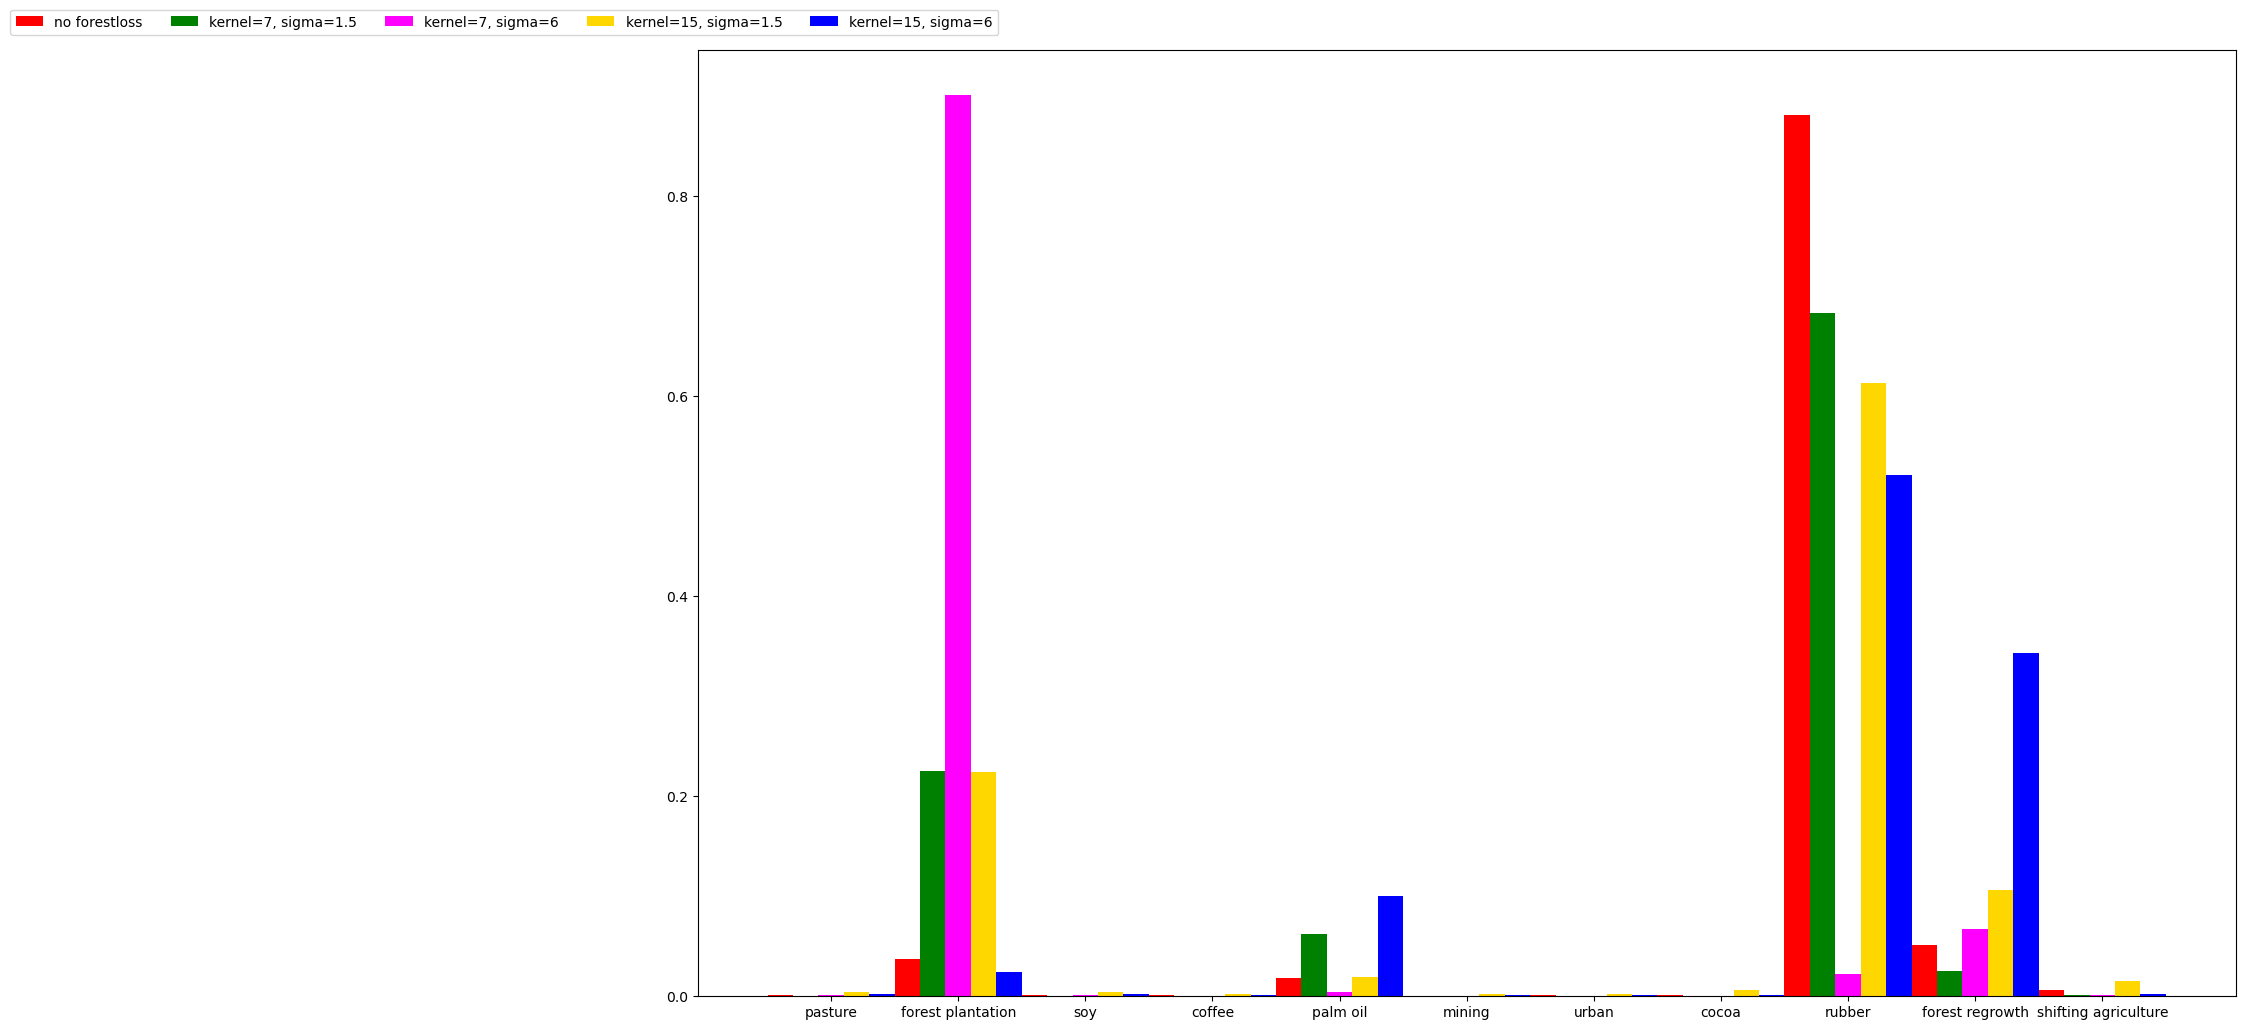

forest plantation


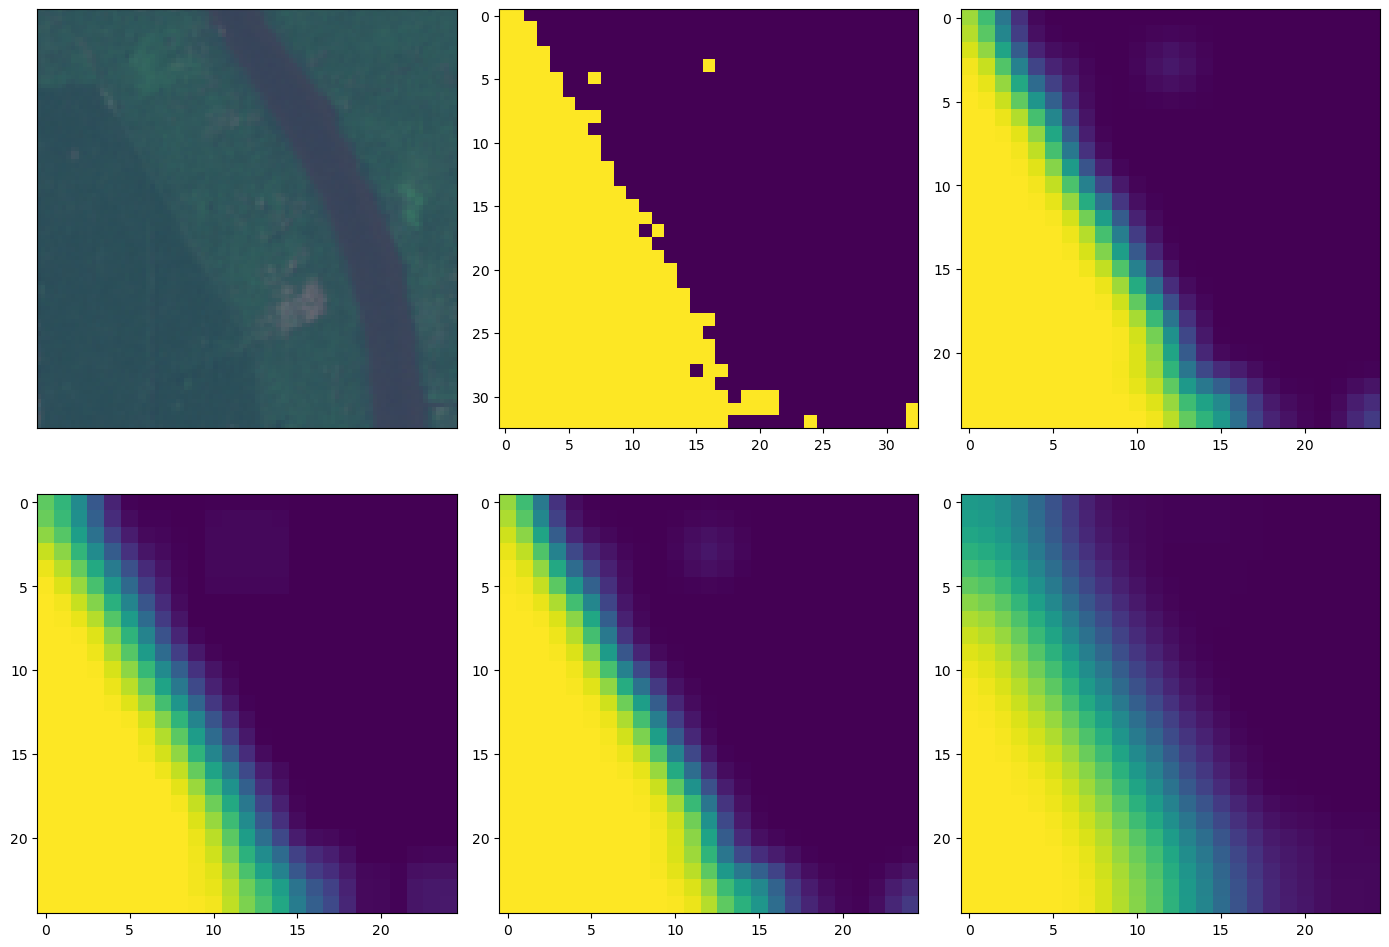

In [72]:
df = models['no forestloss']['val_dl'].dataset.img_labels

for sampleid in sampleids:
    print(sampleid)
    idx = df.loc[df.sampleid == sampleid].index.values[0]
    
    for model_name in models.keys():
        
        if model_name == 'no forestloss':
            _input, label = models[model_name]['val_dl'].dataset.__getitem__(idx)
            _input = _input.unsqueeze(dim=0)
            prediction = models[model_name]['model'](_input)
        else:
            batch, label = models[model_name]['val_dl'].dataset.__getitem__(idx)
            _input, forestloss = batch
            _input = _input.unsqueeze(dim=0)
            forestloss =  forestloss.unsqueeze(dim=0)
            prediction = models[model_name]['model'](_input, forestloss)
            models[model_name]['forestloss'] = forestloss.squeeze().numpy()

        
        models[model_name]['probabilities'] = F.softmax(prediction, dim=1).detach().cpu().numpy()
    
    plot_predictions(models, classes)
    
    #Gather all blurred forestloss patches
    forestloss_patches = [
        models[model_name]['forestloss']
        for model_name in models.keys() 
        if 'forestloss' in models[model_name].keys()]
    
    #Add the original forestloss patch
    with rasterio.open(f'../data/forestloss_tiles/{str(sampleid)}.tif') as src:
        data = src.read()

    forestloss_patches.insert(0, data.squeeze())

    
        
    plot_image_with_tmfs(_input.squeeze(), forestloss_patches,  label= inverse_label_mapping[label])


    _waitforinput = input()

    clear_output(wait=True)

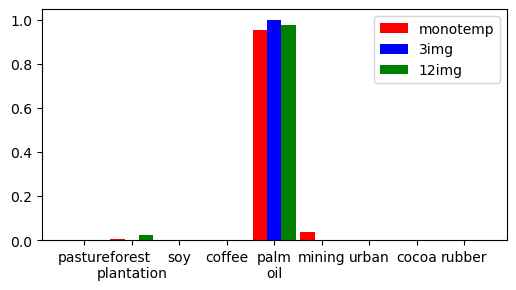

Ground truth:  palm oil


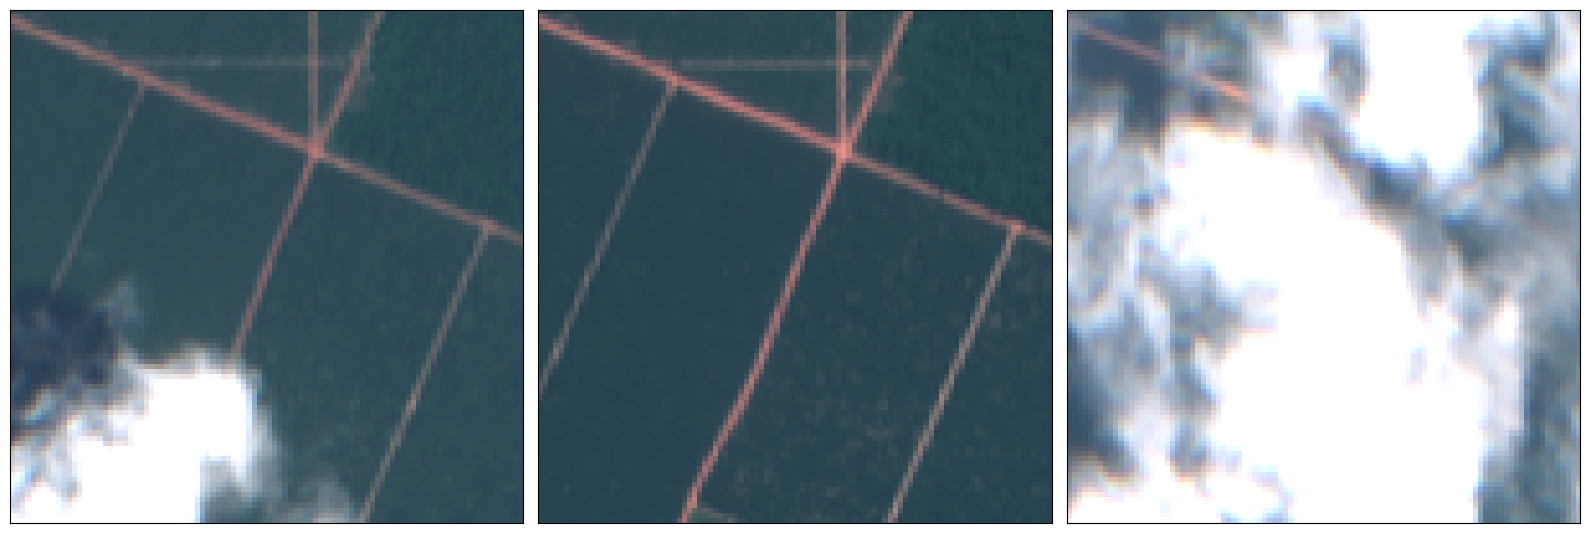

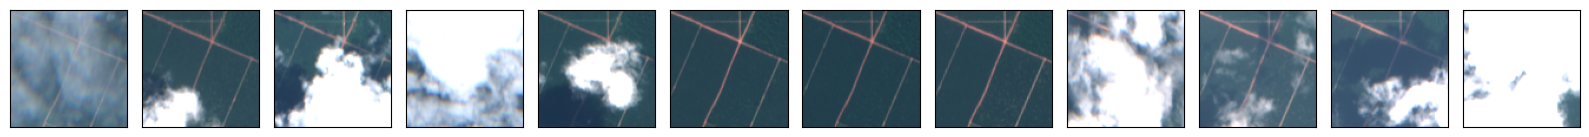

KeyboardInterrupt: Interrupted by user

In [126]:
dataset = models['no forestloss']['val_dl'].dataset

for sampleid in sampleids:
    
    idx = dataset.img_labels.loc[dataset.img_labels.sampleid == sampleids[0]].index.values[0]
    
    batch, label = dataset.__getitem__(idx)
    _input, forestloss = batch
    _input = _input.unsqueeze(dim=0)
    
    for model in models:
        models[model]['probabilities'] = F.softmax(models[model]['model'](_input), dim=1).detach().cpu().numpy()

    plot_predictions(models, classes)
        

    plot_images(input_3img, label= inverse_label_mapping[label])
    plot_images(input_12img)

    _waitforinput = input()

    clear_output(wait=True)

## Predict the entire validation set with all models and find where TMF results in an incorrect preds

In [103]:
import importlib
import evaluate  # Import the module, not the function
importlib.reload(evaluate)
from evaluate import evaluate  # Re-import the function after reloading the module

In [20]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

for model_name, value in models.items():
    print(model_name)
    value['model'].to(device)
    loss_fn = nn.CrossEntropyLoss(reduction='mean')

    value['config']['wandb']['log_to_wandb'] = False
    metrics, preds, targets = evaluate(
        model=value['model'], 
        loss_fn=loss_fn, 
        dataloader=value['val_dl'], 
        device=device, 
        config=value['config'],
        return_preds_and_targets=True
    )
    
    models[model_name]['predictions'] = preds
    models[model_name]['metrics'] = metrics
    

layer=2; kernel=15, sigma=1.5
layer=1; kernel=7, sigma=5
layer=2; kernel=7, sigma=5
layer=3; kernel=7, sigma=5


In [25]:
pd.DataFrame(models['layer=2; kernel=15, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.763608,0.613946,0.915222,0.084746,0.776965,0.968750,0.916586,0.735786,0.826347,0.645510,0.724638,0.798803,0.724737,0.810129,0.643838
recall,0.869796,0.702335,0.908801,0.178571,0.652341,0.874119,0.948795,0.995475,0.650067,0.779136,0.670641,0.798803,0.748189,0.798803,0.643838
f1-score,0.813251,0.655172,0.912000,0.114943,0.709220,0.919005,0.932412,0.846154,0.727684,0.706056,0.696594,0.798803,0.730226,0.800062,0.643838
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.798803,11864.000000,11864.000000,0.643838


In [26]:
pd.DataFrame(models['layer=1; kernel=7, sigma=5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.772685,0.678436,0.850058,0.156250,0.626632,0.879771,0.936053,0.898520,0.749799,0.680592,0.656699,0.774107,0.716863,0.774627,0.842202
recall,0.731621,0.523346,0.940051,0.178571,0.736761,0.928499,0.852410,0.961538,0.627187,0.637327,0.818182,0.774107,0.721409,0.774107,0.842202
f1-score,0.751592,0.590884,0.892792,0.166667,0.677249,0.903479,0.892275,0.928962,0.683034,0.658249,0.728600,0.774107,0.715798,0.771086,0.842202
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.774107,11864.000000,11864.000000,0.842202


In [27]:
pd.DataFrame(models['layer=2; kernel=7, sigma=5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.759434,0.655721,0.812202,0.138889,0.806904,0.963776,0.885005,0.912206,0.804587,0.634653,0.765027,0.798045,0.739855,0.804677,0.645937
recall,0.855624,0.641051,0.976403,0.178571,0.574060,0.884189,0.965863,0.963801,0.590175,0.797066,0.834575,0.798045,0.751034,0.798045,0.645937
f1-score,0.804665,0.648303,0.886765,0.156250,0.670852,0.922269,0.923668,0.937294,0.680901,0.706647,0.798289,0.798045,0.739628,0.794359,0.645937
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.798045,11864.000000,11864.000000,0.645937


In [28]:
pd.DataFrame(models['layer=3; kernel=7, sigma=5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.842975,0.608445,0.907350,0.153846,0.603306,0.960526,0.974026,0.823417,0.853748,0.663759,0.679883,0.792987,0.733753,0.806754,0.744877
recall,0.722764,0.616732,0.936862,0.214286,0.840368,0.918933,0.903614,0.970588,0.628533,0.682152,0.690015,0.792987,0.738622,0.792987,0.744877
f1-score,0.778255,0.612560,0.921870,0.179104,0.702373,0.939269,0.937500,0.890966,0.724031,0.672830,0.684911,0.792987,0.731243,0.794678,0.744877
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.792987,11864.000000,11864.000000,0.744877


In [164]:
np.unique(models['layer=1; kernel=15, sigma=1.5']['predictions'], return_counts=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
 array([ 668,  287, 1252,    1,  781,  360,  144,   65,  152, 8071,   83]))

In [165]:
np.unique(models['layer=2; kernel=15, sigma=1.5']['predictions'], return_counts=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
 array([1286, 1176, 1557,   59, 1094, 1792, 1031,  598, 1169, 1481,  621]))

In [166]:
np.unique(models['layer=3; kernel=15, sigma=1.5']['predictions'], return_counts=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
 array([1037, 1152, 1658,   49, 1312, 1786, 1033,  414, 1228, 1288,  907]))

In [143]:
df = value['val_dl'].dataset.img_labels.copy(deep=True) 

In [148]:
for model_name, value in models.items():
    models_preds = models[model_name]['predictions']
    df[model_name] = [inverse_label_mapping[item] for item in  models[model_name]['predictions']]

In [149]:
df

,Unnamed: 0,geometry,driver,sampleid,split,"layer=1; kernel=15, sigma=1.5","layer=2; kernel=15, sigma=1.5","layer=3; kernel=15, sigma=1.5"
0,25,POINT (-8.009575847503946 7.674800718585031),cocoa,3000391,val,forest regrowth,shifting agriculture,pasture
1,29,POINT (-4.24608396468521 6.241089525130277),cocoa,3023426,val,forest regrowth,cocoa,pasture
2,41,POINT (-0.6335090495985547 6.316548008996314),cocoa,3021622,val,forest regrowth,cocoa,pasture
3,53,POINT (-0.8598845011966736 6.571220392044198),cocoa,3014714,val,forest regrowth,cocoa,pasture
4,71,POINT (-8.028440468470455 7.344669851671106),cocoa,3001603,val,cocoa,cocoa,cocoa
...,...,...,...,...,...,...,...,...
11859,46519,POINT (-52.175763706847384 -32.09882382981685),urban,1610795,val,forest regrowth,urban,pasture
11860,46520,POINT (-52.10030522298134 -32.09882382981685),urban,1610796,val,forest regrowth,urban,pasture
11861,46521,POINT (11.57627466 3.70730226),urban,6000050,val,forest regrowth,cocoa,pasture
11862,46531,POINT (11.4099965 -1.988196306),urban,6000339,val,forest regrowth,shifting agriculture,pasture


In [144]:
for model_name, value in models.items():
    print(model_name)
    #x = pd.DataFrame(models[model_name]['metrics'])
    #break

layer=1; kernel=15, sigma=1.5
layer=2; kernel=15, sigma=1.5
layer=3; kernel=15, sigma=1.5


In [145]:
pd.DataFrame(models['layer=1; kernel=15, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.845808,0.742160,0.913738,0.0,0.670935,0.972222,0.833333,0.784615,0.565789,0.147441,0.385542,0.360334,0.623780,0.709106,4.02372
recall,0.500443,0.207198,0.729592,0.0,0.402149,0.176234,0.120482,0.115385,0.057873,0.969845,0.047690,0.360334,0.302445,0.360334,4.02372
f1-score,0.628826,0.323954,0.811348,0.0,0.502879,0.298380,0.210526,0.201183,0.105006,0.255969,0.084881,0.360334,0.311178,0.369915,4.02372
support,1129.000000,1028.000000,1568.000000,28.0,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.360334,11864.000000,11864.000000,4.02372


In [146]:
pd.DataFrame(models['layer=2; kernel=15, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.763608,0.613946,0.915222,0.084746,0.776965,0.968750,0.916586,0.735786,0.826347,0.645510,0.724638,0.798803,0.724737,0.810129,0.643838
recall,0.869796,0.702335,0.908801,0.178571,0.652341,0.874119,0.948795,0.995475,0.650067,0.779136,0.670641,0.798803,0.748189,0.798803,0.643838
f1-score,0.813251,0.655172,0.912000,0.114943,0.709220,0.919005,0.932412,0.846154,0.727684,0.706056,0.696594,0.798803,0.730226,0.800062,0.643838
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.798803,11864.000000,11864.000000,0.643838


In [147]:
pd.DataFrame(models['layer=3; kernel=15, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.124067,0.647450,0.686508,0.0,0.805046,0.984615,0.789474,0.680851,0.777778,0.307692,0.500000,0.269892,0.573044,0.661040,5.211259
recall,0.971656,0.284047,0.661990,0.0,0.269378,0.096677,0.030120,0.144796,0.051817,0.048900,0.001490,0.269892,0.232807,0.269892,5.211259
f1-score,0.220038,0.394861,0.674026,0.0,0.403680,0.176066,0.058027,0.238806,0.097161,0.084388,0.002972,0.269892,0.213639,0.252878,5.211259
support,1129.000000,1028.000000,1568.000000,28.0,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.269892,11864.000000,11864.000000,5.211259


In [132]:
pd.DataFrame(models['no forestloss']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.797784,0.580920,0.912476,0.111111,0.625899,0.908861,0.972129,0.71637,0.785448,0.663866,0.699860,0.771662,0.706793,0.782916,0.827781
recall,0.765279,0.663424,0.890944,0.250000,0.801228,0.903827,0.875502,1.00000,0.566622,0.579462,0.743666,0.771662,0.730905,0.771662,0.827781
f1-score,0.781193,0.619437,0.901581,0.153846,0.702794,0.906337,0.921289,0.83475,0.658327,0.618799,0.721098,0.771662,0.710859,0.772119,0.827781
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.00000,1486.000000,1227.000000,671.000000,0.771662,11864.000000,11864.000000,0.827781


In [133]:
pd.DataFrame(models['kernel=7, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.853682,0.501805,0.939015,0.148936,0.618047,0.951258,0.925709,0.857988,0.807459,0.663220,0.852941,0.783294,0.738187,0.803939,0.688396
recall,0.780337,0.676070,0.815051,0.250000,0.767460,0.913897,0.950803,0.984163,0.626514,0.731866,0.605067,0.783294,0.736475,0.783294,0.688396
f1-score,0.815363,0.576046,0.872653,0.186667,0.684697,0.932203,0.938088,0.916754,0.705570,0.695854,0.707934,0.783294,0.730166,0.787815,0.688396
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.783294,11864.000000,11864.000000,0.688396


In [134]:
pd.DataFrame(models['kernel=7, sigma=6']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.768852,0.560209,0.884684,0.162791,0.778626,0.935780,0.960905,0.883090,0.898465,0.556976,0.878553,0.787761,0.751721,0.814574,0.683658
recall,0.830824,0.728599,0.954082,0.250000,0.626247,0.924471,0.937751,0.957014,0.512113,0.852486,0.506706,0.787761,0.734572,0.787761,0.683658
f1-score,0.798638,0.633404,0.918073,0.197183,0.694173,0.930091,0.949187,0.918567,0.652379,0.673752,0.642722,0.787761,0.728015,0.786271,0.683658
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.787761,11864.000000,11864.000000,0.683658


In [135]:
pd.DataFrame(models['kernel=15, sigma=1.5']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.763608,0.613946,0.915222,0.084746,0.776965,0.968750,0.916586,0.735786,0.826347,0.645510,0.724638,0.798803,0.724737,0.810129,0.643838
recall,0.869796,0.702335,0.908801,0.178571,0.652341,0.874119,0.948795,0.995475,0.650067,0.779136,0.670641,0.798803,0.748189,0.798803,0.643838
f1-score,0.813251,0.655172,0.912000,0.114943,0.709220,0.919005,0.932412,0.846154,0.727684,0.706056,0.696594,0.798803,0.730226,0.800062,0.643838
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.798803,11864.000000,11864.000000,0.643838


In [136]:
pd.DataFrame(models['kernel=15, sigma=6']['metrics'])

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg,loss
precision,0.800360,0.686676,0.920132,0.152778,0.648365,0.942348,0.958290,0.830769,0.744847,0.683554,0.663265,0.793071,0.730126,0.799490,0.750009
recall,0.788308,0.456226,0.889031,0.392857,0.806600,0.905337,0.922691,0.977376,0.705249,0.714751,0.774963,0.793071,0.757581,0.793071,0.750009
f1-score,0.794288,0.548217,0.904314,0.220000,0.718878,0.923472,0.940153,0.898129,0.724507,0.698805,0.714777,0.793071,0.735049,0.792497,0.750009
support,1129.000000,1028.000000,1568.000000,28.000000,1303.000000,1986.000000,996.000000,442.000000,1486.000000,1227.000000,671.000000,0.793071,11864.000000,11864.000000,0.750009
